# 04 · Radial compliance (RCA-2)
[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/rusparrish/visual-thinking-lens/blob/main/notebooks/04_radial_compliance.ipynb)

Does mass fall off in rings, and around **which** center? Rings around the frame center are the global default basin; rings around the mass's own centroid mean the subject organizes the frame.

`RC = 1 − JSD(observed radial profile, best exponential decay)`

In [1]:
# Works locally (pip install -e .) or in Colab.
try:
    import vtl
except ImportError:
    %pip install -q git+https://github.com/rusparrish/visual-thinking-lens
    import vtl
from pathlib import Path
IMAGES = Path("../examples/images") if Path("../examples/images").exists() else None
if IMAGES is None:  # Colab: fetch the sample images
    !git clone -q --depth 1 https://github.com/rusparrish/visual-thinking-lens /content/vtl-repo
    IMAGES = Path("/content/vtl-repo/examples/images")
print("vtl", vtl.__version__, "| images:", IMAGES)

vtl 0.1.0 | images: ../examples/images


In [2]:
s, f = vtl.measure_radial(IMAGES / "portrait.jpg", return_fields=True)
{k: (round(v, 3) if isinstance(v, float) else v) for k, v in s.items()}

{'mask_mode': 'subject',
 'RC_f': 0.558,
 'JSD_f': 0.442,
 'alpha_f': 0.105,
 'RC_s': 0.493,
 'JSD_s': 0.507,
 'alpha_s': 1.133,
 'dRC': -0.065,
 'dx': 0.066,
 'dy': -0.288,
 'dr': 0.296,
 'void_ratio': 0.767,
 'E_s': 0.452,
 'compactness': 0.345,
 'isotropy': 0.372,
 'ang_mean': 0.375,
 'radially_ineligible': False,
 'radial_label': 'Field-dominant radial collapse (global basin wins)',
 'default_prior': False,
 'default_prior_reasons': 'E_s<0.55; delta_r>0.12; RC_f<0.7',
 'radial_version': 'rca2-5.21'}

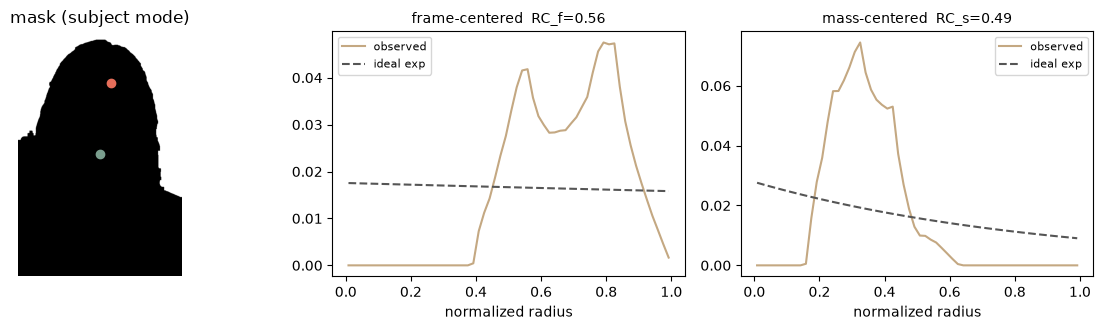

In [3]:
import matplotlib.pyplot as plt, numpy as np
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
axes[0].imshow(f["mask"], cmap="gray"); axes[0].set_title("mask (subject mode)"); axes[0].axis("off")
for (cx, cy), col in [(f["frame_center"], "#7a9e8e"), (f["mass_center"], "#e66e5a")]:
    axes[0].plot(cx, cy, "o", color=col)
for ax, p, q, title in [(axes[1], f["p_frame"], f["q_frame"], f"frame-centered  RC_f={s['RC_f']:.2f}"),
                        (axes[2], f["p_mass"], f["q_mass"], f"mass-centered  RC_s={s['RC_s']:.2f}")]:
    ax.plot(f["r"], p, color="#c4a882", label="observed")
    ax.plot(f["r"], q / q.sum(), color="#555", ls="--", label="ideal exp")
    ax.set_title(title, fontsize=10); ax.set_xlabel("normalized radius"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

- `dRC = RC_s − RC_f`: positive → rings follow the subject; negative → the frame center wins.
- `E_s` (eligibility) gates interpretation: below 0.38 the mask isn't round/compact enough for RC_s to mean anything.
- `default_prior` is the RDC gate: True means "this reads as a center-default composition". False is not "bad".

In [4]:
import pandas as pd
pd.DataFrame([{"image": p.stem, **vtl.measure_radial(p)} for p in sorted(IMAGES.glob("*.jpg"))])[
    ["image", "RC_f", "RC_s", "dRC", "E_s", "radial_label", "default_prior"]].round(3)

,image,RC_f,RC_s,dRC,E_s,radial_label,default_prior
0,abstract,0.631,0.631,0.000,0.455,Radial present (dual-center / near-tie),False
1,collapse,0.703,0.590,-0.113,0.449,Field-dominant radial collapse (global basin w...,False
2,drawing,0.678,0.644,-0.033,0.374,Mass present but radially ineligible (do not i...,False
3,frog,0.503,0.632,0.129,0.332,Mass present but radially ineligible (do not i...,False
4,landscape,0.471,0.623,0.152,0.440,Subject-dominant radial (rings follow mass),False
5,portrait,0.558,0.493,-0.065,0.452,Field-dominant radial collapse (global basin w...,False
6,room,0.438,0.619,0.181,0.361,Mass present but radially ineligible (do not i...,False
7,still_life,0.549,0.644,0.095,0.376,Mass present but radially ineligible (do not i...,False
8,study,0.620,0.626,0.007,0.502,Radial present (dual-center / near-tie),False
9,walking,0.477,0.567,0.090,0.418,Subject-dominant radial (rings follow mass),False
